In [1]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis

Foram criadas 3 pastas a partir das imagens originais. Uma das pastas recebeu as imagens sem marcador, outra pasta recebeu as imagens marcadas sem rótulo e a terceira pasta recebeu as imagens marcadas com os rótulos. Nesse notebook, estamos trabalhando com 40 (iniciais) imagens marcadas com os rótulos.

In [2]:
os.listdir("./data/")

['imagem_conjunto',
 'imagens de contraste de fase (CHO745)',
 'imagens de fluorescencia',
 'realcadas_verde_HBMEC',
 'realcadas_verde_HUVEC']

In [3]:
novas_imagens = "./data/realcadas_verde_HBMEC/"
img_key = 0 #Chave da primeira imagem

lista_novas_img = [i for i in os.listdir(novas_imagens) if i.endswith('.tif')] #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens
# lista_novas_img

31

Visualização das imagens (x): Melhor resolução 300x300

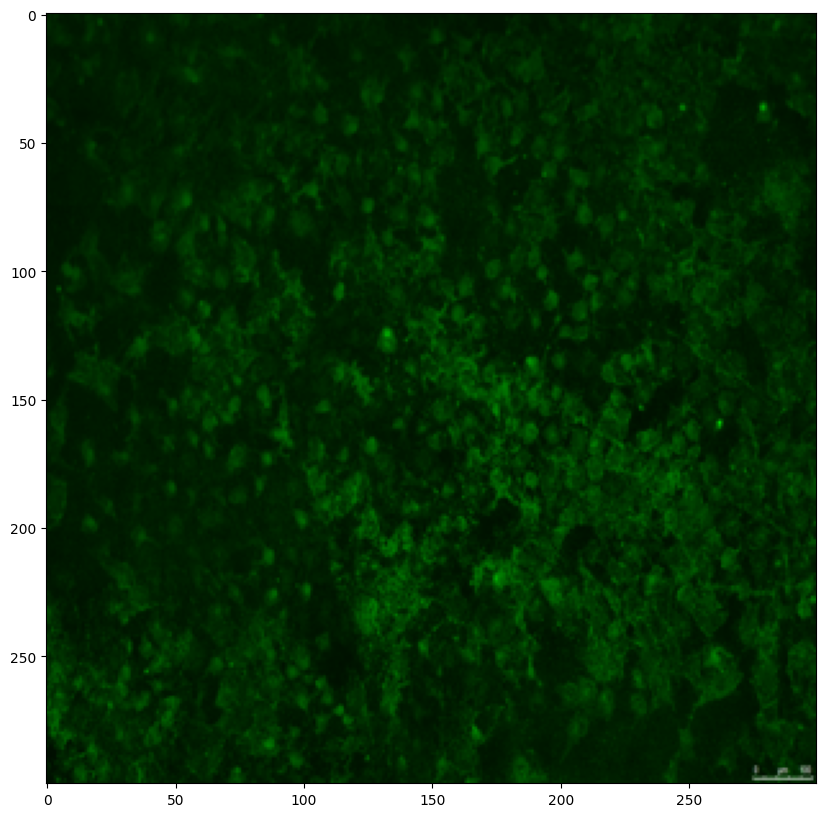

In [4]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

#1. Original orientation of the image.

Formatting all images that are saved in the directory into an array

In [5]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img] #cortando informações da imagem
y_rotulo_imagem = [(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = y_rotulo_imagem
print(len(y_rotulo_imagem)) #verificando o numero de rótulos corresponde o numero de imagens
print(y_rotulo_imagem)

31
['0.154757', '0.138553', '0.160986', '0.127821', '0.180817', '0.164756', '0.166864', '0.188495', '0.163527', '0.154551', '0.435090', '0.173011', '0.408415', '0.307947', '0.428906', '0.436615', '0.403093', '0.371291', '0.370098', '0.318978', '0.186781', '0.223602', '0.216760', '0.185403', '0.229978', '0.195044', '0.197190', '0.231501', '0.173558', '0.190686', '0.165657']


In [6]:
lista_imagens_camp_claro = [] #lista vazia onde vai ser armazenado os dados
for file in lista_novas_img[:]:  #laço pra salvar todas as imagens
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test) #abrir a imagem
    img = img.resize(resize_img) #formatando em 300x300
    img = np.asarray(img)[:,:,:3] #formatando em array
    lista_imagens_camp_claro.append(img)  #adicionando cada imagem
np.asarray(lista_imagens_camp_claro).shape #verificando quantas imagens foram salvas em qual tamnho e camadas

(31, 300, 300, 3)

#2. Saving inverted images from left to right

label (80 - doubled) - dobrando o numero de rótulos

In [7]:
# #dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

62

In [8]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(62, 300, 300, 3)

#3. Saving inverted images from bottom to top

y = label (120 - doubled)

In [9]:
# #dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

93

In [10]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(93, 300, 300, 3)

# 4. Saving the images flipped upside down.

label (160 - doubled) - dobrando o numero de rótulos

In [11]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

124

In [12]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(124, 300, 300, 3)

Salvando em uma lista as imagens em diferentes orientações.

In [13]:
data = timeProcess()[1]
# joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}save/lista_imagem_100_resized_regre_HBMEC_realce_'+data+'.gz')

# Modificando o banco com angulação

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import convolve

In [15]:
# 1. Simular um lote de 124 imagens com formato (124, 300, 300, 3) e escala de 0 a 250
np.random.seed(42)
num_imagens, altura, largura, canais = 124, 300, 300, 3
lote_imagens = np.zeros((num_imagens, altura, largura, canais), dtype=np.float32)

# Preenchendo algumas formas para teste em todas as imagens do lote
lote_imagens[:, 90:210, 90:210, 0] = 50.0   # Vermelho
lote_imagens[:, 90:210, 90:210, 1] = 220.0  # Verde
lote_imagens[:, 90:210, 90:210, 2] = 80.0   # Azul
lote_imagens[:, 130:170, 30:270, 2] = 250.0  # Azul cruzado
lote_imagens.shape

(124, 300, 300, 3)

In [16]:
lote_imagens = np.asarray(lista_imagens_camp_claro)
lote_imagens.shape

(124, 300, 300, 3)

In [17]:
# 2. Funções com parâmetros ajustados para um efeito MAIS DISCRETO
def aplicar_motion_blur_discreto(img_3d, tamanho_kernel=5, direcao='diagonal'):
    # Tamanho menor (ex: 5 em vez de 15) deixa o desfoque sutil
    kernel = np.zeros((tamanho_kernel, tamanho_kernel))
    if direcao == 'horizontal':
        kernel[tamanho_kernel // 2, :] = 1
    elif direcao == 'vertical':
        kernel[:, tamanho_kernel // 2] = 1
    elif direcao == 'diagonal':
        np.fill_diagonal(kernel, 1)
    
    kernel /= kernel.sum()
    
    img_blur = np.zeros_like(img_3d)
    for c in range(img_3d.shape[2]):
        img_blur[..., c] = convolve(img_3d[..., c], kernel)
    return img_blur


def aplicar_jitter_discreto(img_3d, fator_tremor=1):
    # Fator menor (ex: 1 ou 2 em vez de 6) faz o pixel se mover bem pouco
    h, w, c = img_3d.shape
    di = np.random.randint(-fator_tremor, fator_tremor + 1, size=(h, w))
    dj = np.random.randint(-fator_tremor, fator_tremor + 1, size=(h, w))
    
    grid_i, grid_j = np.ogrid[:h, :w]
    novas_i = np.clip(grid_i + di, 0, h - 1)
    novas_j = np.clip(grid_j + dj, 0, w - 1)
    
    return img_3d[novas_i, novas_j]

In [18]:
# 3. Aplicando as funções em todo o lote (124 imagens)
lote_motion_blur = np.empty_like(lote_imagens)
lote_jitter = np.empty_like(lote_imagens)

for idx in range(num_imagens):
    lote_motion_blur[idx] = aplicar_motion_blur_discreto(lote_imagens[idx], tamanho_kernel=5)
    lote_jitter[idx] = aplicar_jitter_discreto(lote_imagens[idx], fator_tremor=1)

print(f"Shape final do lote com Motion Blur: {lote_motion_blur.shape}")
print(f"Shape final do lote com Jitter: {lote_jitter.shape}")

Shape final do lote com Motion Blur: (124, 300, 300, 3)
Shape final do lote com Jitter: (124, 300, 300, 3)


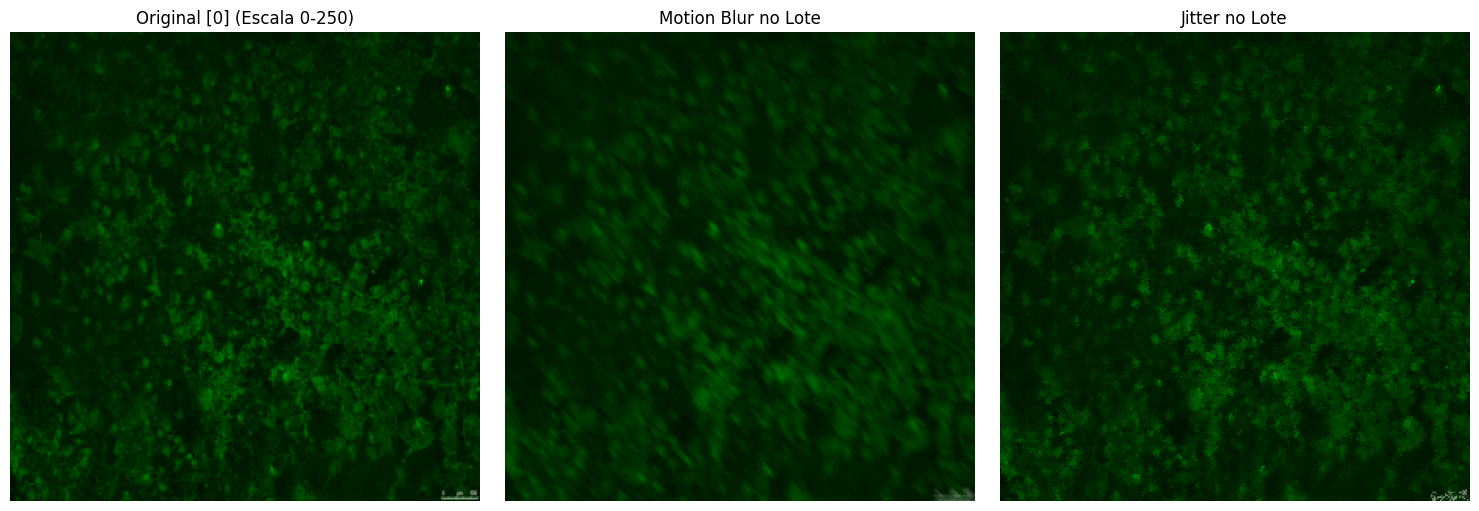

In [19]:
c = 0
# 4. Exemplo de visualização da primeira imagem do lote (índice 0)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(np.clip(lote_imagens[c] / 250.0, 0, 1))
axes[0].set_title('Original [0] (Escala 0-250)')
axes[0].axis('off')

axes[1].imshow(np.clip(lote_motion_blur[c] / 250.0, 0, 1))
axes[1].set_title('Motion Blur no Lote')
axes[1].axis('off')

axes[2].imshow(np.clip(lote_jitter[c] / 250.0, 0, 1))
axes[2].set_title('Jitter no Lote')
axes[2].axis('off')

plt.tight_layout()
plt.show()

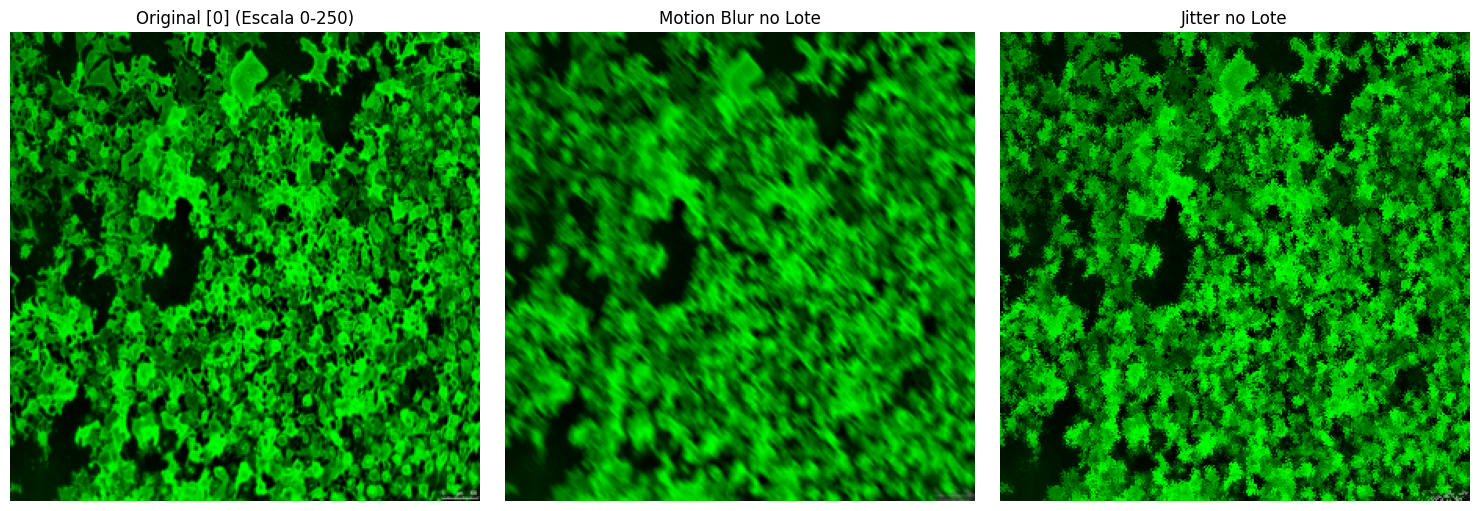

In [20]:
c = 10
# 4. Exemplo de visualização da primeira imagem do lote (índice 0)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(np.clip(lote_imagens[c] / 250.0, 0, 1))
axes[0].set_title('Original [0] (Escala 0-250)')
axes[0].axis('off')

axes[1].imshow(np.clip(lote_motion_blur[c] / 250.0, 0, 1))
axes[1].set_title('Motion Blur no Lote')
axes[1].axis('off')

axes[2].imshow(np.clip(lote_jitter[c] / 250.0, 0, 1))
axes[2].set_title('Jitter no Lote')
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [21]:
for _ in range(8):
    y_rotulo_soma += y_rotulo_imagem
    print(len(y_rotulo_soma))

155
186
217
248
279
310
341
372


In [24]:
joblib.dump(lote_jitter, f'{novas_imagens}save/lista_imagem_100_jitter_regre_HBMEC_realce_'+data+'.gz')
joblib.dump(lote_motion_blur, f'{novas_imagens}save/lista_imagem_100_motion_regre_HBMEC_realce_'+data+'.gz')

['./data/realcadas_verde_HBMEC/save/lista_imagem_100_motion_regre_HBMEC_realce_2026-10-18.gz']

In [25]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}save/lista_rotulo_100_angulo_regre_balb-roseta_'+data+'.gz')

['./data/realcadas_verde_HBMEC/save/lista_rotulo_100_angulo_regre_balb-roseta_2026-10-18.gz']